# SafeTech Insights – Sentiment Analysis

## 1. Introduction

This notebook analyzes user reviews of personal safety applications using Natural Language Processing (NLP) and Machine Learning.

## 2. Objectives

- Explore user reviews and ratings.
- Clean and prepare the text data.
- Analyze sentiment patterns.
- Train and evaluate sentiment classification models.
- Compare different machine learning approaches.

## 3. Dataset

The dataset contains 6,527 user reviews collected from 15 personal safety applications.  

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing and machine learning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix
)

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

ModuleNotFoundError: No module named 'sklearn'

In [1]:
%pip install scikit-learn pandas numpy matplotlib seaborn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.3 MB 1.0 MB/s eta 0:00:08
   --- ------------------------------------ 0.8/8.3 MB 1.0 MB/s eta 0:00:08
   ------- -------------------------------- 1.6/8.3 MB 1.4 MB/s eta 0:00:05
   ---------- ----------------------------- 2.1/8.3 MB 1.7 MB/s eta 0:00:04
   --------------- ------------------------ 3.1/8.3 MB 2.1 MB/s eta 0:00:03
   -------------------- ------------------- 4.2/8.3 MB 2.5 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.3 MB 2.8 MB/s eta 0:00:02
   ------------------------------ --------- 6.3/8.3 MB 3.0 MB/s eta 0:00:01
   ------------------------------------ --- 7.6/8.3 MB 3.3 MB/s eta 0:00:01
   -------------------------------------

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing and machine learning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix
)

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
import pandas as pd

file_path = "../Data/Personal_Safety_Application_Reviews-M4POVQ - Copy.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (6527, 4)


,ID,App_name,Rating,Review_Text
0,1,bSafe,1,i sent so many request to get messge to activa...
1,2,bSafe,1,I try byt I can't verify my number
2,3,bSafe,1,DANGEROUS!! No tutorial whatsoever so I have n...
3,4,bSafe,5,Try to mee
4,5,bSafe,1,"Used to be a great app, but now it doesn't let..."


In [6]:
# Display dataset information
print("Dataset Information:")
df.info()

# Check dataset dimensions
print("\nDataset Shape:")
print(df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all'))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6527 entries, 0 to 6526
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ID           6527 non-null   int64 
 1   App_name     6527 non-null   object
 2   Rating       6527 non-null   int64 
 3   Review_Text  6521 non-null   object
dtypes: int64(2), object(2)
memory usage: 204.1+ KB

Dataset Shape:
(6527, 4)

Missing Values:
ID             0
App_name       0
Rating         0
Review_Text    6
dtype: int64

Duplicate Rows:
0

Statistical Summary:


,ID,App_name,Rating,Review_Text
count,6527.000000,6527,6527.000000,6521
unique,NaN,15,NaN,4953
top,NaN,bSafe,NaN,Good
freq,NaN,1000,NaN,200
mean,3264.000000,NaN,3.612992,NaN
std,1884.326936,NaN,1.713837,NaN
min,1.000000,NaN,1.000000,NaN
25%,1632.500000,NaN,1.000000,NaN
50%,3264.000000,NaN,5.000000,NaN
75%,4895.500000,NaN,5.000000,NaN


In [7]:
# Create a clean copy of the dataset
df_clean = df.dropna(subset=['Review_Text']).copy()

# Remove extra spaces from reviews
df_clean['Review_Text'] = df_clean['Review_Text'].str.strip()

# Remove empty reviews
df_clean = df_clean[df_clean['Review_Text'] != '']

# Display cleaning results
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Missing reviews:", df_clean['Review_Text'].isnull().sum())

df_clean.head()

Original dataset: (6527, 4)
Cleaned dataset: (6521, 4)
Missing reviews: 0


,ID,App_name,Rating,Review_Text
0,1,bSafe,1,i sent so many request to get messge to activa...
1,2,bSafe,1,I try byt I can't verify my number
2,3,bSafe,1,DANGEROUS!! No tutorial whatsoever so I have n...
3,4,bSafe,5,Try to mee
4,5,bSafe,1,"Used to be a great app, but now it doesn't let..."


In [8]:
# Assign sentiment labels based on star ratings
def assign_sentiment(rating):
    if rating <= 2:
        return 'Negative'
    elif rating == 3:
        return 'Neutral'
    else:
        return 'Positive'

# Create sentiment column
df_clean['Sentiment'] = df_clean['Rating'].apply(assign_sentiment)

# Display sentiment distribution
print("Sentiment Distribution:")
print(df_clean['Sentiment'].value_counts())

# Preview the updated dataset
df_clean.head()

Sentiment Distribution:
Sentiment
Positive    4117
Negative    2009
Neutral      395
Name: count, dtype: int64


,ID,App_name,Rating,Review_Text,Sentiment
0,1,bSafe,1,i sent so many request to get messge to activa...,Negative
1,2,bSafe,1,I try byt I can't verify my number,Negative
2,3,bSafe,1,DANGEROUS!! No tutorial whatsoever so I have n...,Negative
3,4,bSafe,5,Try to mee,Positive
4,5,bSafe,1,"Used to be a great app, but now it doesn't let...",Negative


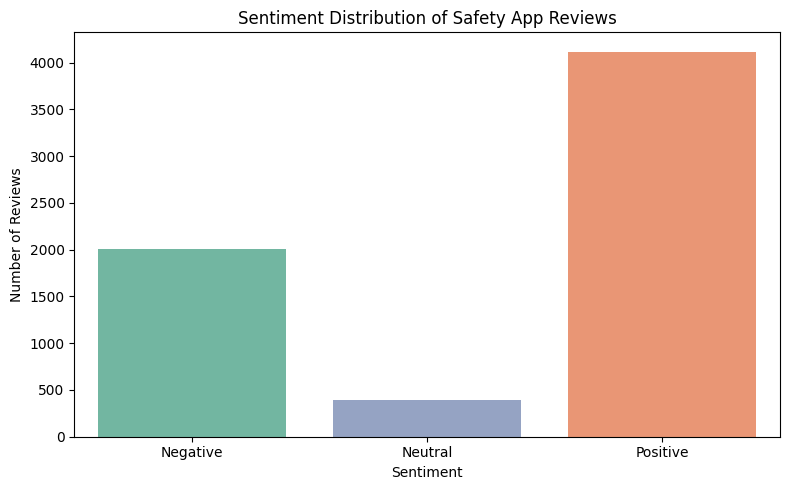

In [9]:
# Visualize sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='Sentiment',
    order=['Negative', 'Neutral', 'Positive'],
    hue='Sentiment',
    palette='Set2',
    legend=False
)

plt.title('Sentiment Distribution of Safety App Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.tight_layout()
plt.show()

,Word,Frequency
0,app,2594
4,good,1090
5,great,655
16,use,510
8,location,493
11,nice,402
12,phone,378
14,time,313
3,family,313
9,love,310


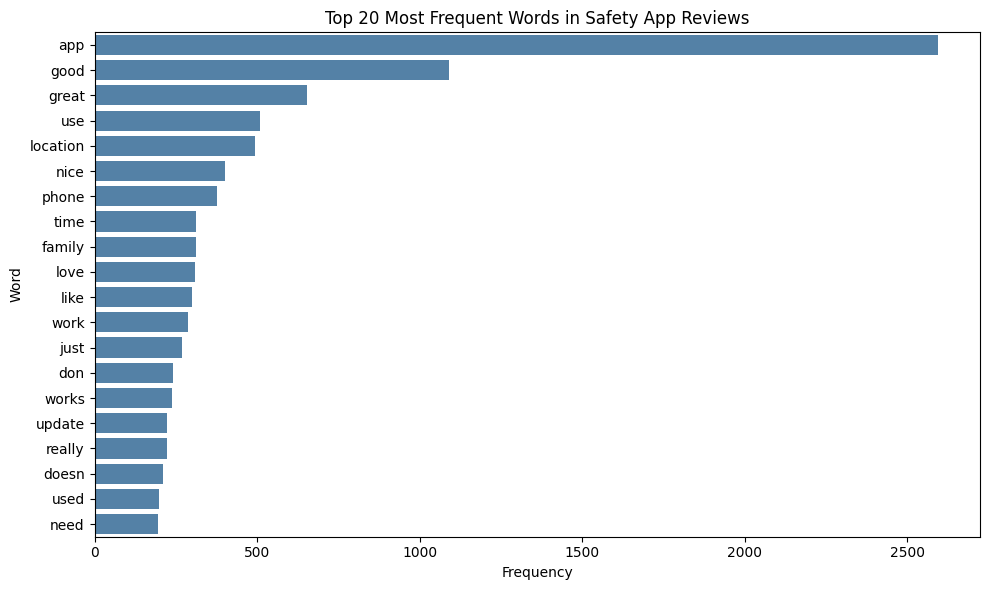

In [10]:
from sklearn.feature_extraction.text import CountVectorizer

# Convert reviews into word counts
vectorizer = CountVectorizer(
    stop_words='english',
    max_features=20
)

word_matrix = vectorizer.fit_transform(df_clean['Review_Text'])

# Calculate word frequencies
word_counts = word_matrix.sum(axis=0).A1
words = vectorizer.get_feature_names_out()

# Create a DataFrame
word_frequency = pd.DataFrame({
    'Word': words,
    'Frequency': word_counts
}).sort_values(by='Frequency', ascending=False)

# Display the results
display(word_frequency)

# Visualize the most frequent words
plt.figure(figsize=(10, 6))

sns.barplot(
    data=word_frequency,
    x='Frequency',
    y='Word',
    color='steelblue'
)

plt.title('Top 20 Most Frequent Words in Safety App Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.show()

In [11]:
# Features: review text
X = df_clean['Review_Text']

# Target: sentiment labels
y = df_clean['Sentiment']

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training samples: 5216
Testing samples: 1305

Training sentiment distribution:
Sentiment
Positive    3293
Negative    1607
Neutral      316
Name: count, dtype: int64

Testing sentiment distribution:
Sentiment
Positive    824
Negative    402
Neutral      79
Name: count, dtype: int64


In [12]:
# Build the sentiment classification pipeline
lr_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        max_features=5000,
        ngram_range=(1, 2)
    )),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train the model
lr_model.fit(X_train, y_train)

# Predict sentiment on test data
y_pred = lr_model.predict(X_test)

# Evaluate the model
print("Model: Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average='macro'), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model: Logistic Regression
Accuracy: 0.7716
Macro F1: 0.6259

Classification Report:
              precision    recall  f1-score   support

    Negative       0.64      0.86      0.73       402
     Neutral       0.29      0.30      0.30        79
    Positive       0.93      0.78      0.85       824

    accuracy                           0.77      1305
   macro avg       0.62      0.65      0.63      1305
weighted avg       0.80      0.77      0.78      1305



In [13]:
# Compare three machine learning models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),
    'Linear SVM': LinearSVC(
        class_weight='balanced',
        random_state=42
    ),
    'Multinomial Naive Bayes': MultinomialNB()
}

results = []

for name, classifier in models.items():

    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(
            stop_words='english',
            max_features=5000,
            ngram_range=(1, 2)
        )),
        ('classifier', classifier)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Macro F1': f1_score(
            y_test, predictions, average='macro'
        )
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by='Macro F1',
    ascending=False
)

display(results_df)

,Model,Accuracy,Macro F1
1,Linear SVM,0.835249,0.662123
0,Logistic Regression,0.771648,0.625878
2,Multinomial Naive Bayes,0.837548,0.590936


In [14]:
# Build Linear SVM pipeline
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english')),
    ('classifier', LinearSVC(
        class_weight='balanced',
        random_state=42
    ))
])

# Hyperparameters to test
parameters = {
    'tfidf__max_features': [3000, 5000, 10000],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'classifier__C': [0.1, 0.5, 1, 2, 5]
}

# Perform grid search
grid_search = GridSearchCV(
    svm_pipeline,
    parameters,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

# Train using training data only
grid_search.fit(X_train, y_train)

# Save best model
best_model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(grid_search.best_score_, 4))

# Evaluate the selected model on test data
best_predictions = best_model.predict(X_test)

print("\nTest Accuracy:")
print(round(accuracy_score(y_test, best_predictions), 4))

print("\nTest Macro F1:")
print(round(f1_score(y_test, best_predictions, average='macro'), 4))

print("\nClassification Report:")
print(classification_report(y_test, best_predictions))

Best Parameters:
{'classifier__C': 0.1, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 2)}

Best Cross-Validation Macro F1:
0.6355

Test Accuracy:
0.8414

Test Macro F1:
0.6757

Classification Report:
              precision    recall  f1-score   support

    Negative       0.75      0.83      0.79       402
     Neutral       0.64      0.23      0.34        79
    Positive       0.90      0.90      0.90       824

    accuracy                           0.84      1305
   macro avg       0.76      0.66      0.68      1305
weighted avg       0.84      0.84      0.83      1305



In [15]:
# Create a DataFrame with actual and predicted labels
error_analysis = pd.DataFrame({
    'Review': X_test.values,
    'Actual': y_test.values,
    'Predicted': best_predictions
})

# Select incorrect predictions
errors = error_analysis[
    error_analysis['Actual'] != error_analysis['Predicted']
]

print("Total incorrect predictions:", len(errors))

# Show examples of incorrectly classified neutral reviews
neutral_errors = errors[errors['Actual'] == 'Neutral']

print("\nIncorrectly classified Neutral reviews:")
display(neutral_errors.head(10))

Total incorrect predictions: 207

Incorrectly classified Neutral reviews:


,Review,Actual,Predicted
55,"Great app, but WHY will it not let you zoom ou...",Neutral,Positive
83,This app use to make me feel safe. Unfortunate...,Neutral,Negative
121,???? ? ???????????????????????????????????????...,Neutral,Positive
152,Drawback only used on mobile data not in wifi,Neutral,Negative
197,why the phone after turn off data and turn on ...,Neutral,Negative
199,It used to work great but now keeps on display...,Neutral,Negative
213,Had this app before and loved it. My phone cra...,Neutral,Negative
225,I really dislike the fact that I can't remove ...,Neutral,Negative
245,Sorta ok...then it just stops. It used to be s...,Neutral,Positive
303,Seems to really drain my battery.,Neutral,Negative


In [16]:
# Create binary dataset
df_binary = df_clean[df_clean['Rating'] != 3].copy()

df_binary['Binary_Sentiment'] = df_binary['Rating'].apply(
    lambda rating: 'Negative' if rating <= 2 else 'Positive'
)

# Features and target
X_binary = df_binary['Review_Text']
y_binary = df_binary['Binary_Sentiment']

# Split the data
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X_binary,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

# Build and train binary SVM model
binary_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        max_features=10000,
        ngram_range=(1, 2)
    )),
    ('classifier', LinearSVC(
        C=0.1,
        class_weight='balanced',
        random_state=42
    ))
])

binary_model.fit(X_train_bin, y_train_bin)

# Evaluate
binary_predictions = binary_model.predict(X_test_bin)

print("Binary Classification Accuracy:",
      round(accuracy_score(y_test_bin, binary_predictions), 4))

print("Binary Classification Macro F1:",
      round(f1_score(y_test_bin, binary_predictions, average='macro'), 4))

print("\nClassification Report:")
print(classification_report(y_test_bin, binary_predictions))

Binary Classification Accuracy: 0.8401
Binary Classification Macro F1: 0.8304

Classification Report:
              precision    recall  f1-score   support

    Negative       0.69      0.92      0.79       402
    Positive       0.95      0.80      0.87       824

    accuracy                           0.84      1226
   macro avg       0.82      0.86      0.83      1226
weighted avg       0.87      0.84      0.84      1226



In [17]:
import joblib
from pathlib import Path

# Create models folder if it doesn't exist
models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

# Save trained models
joblib.dump(best_model, models_dir / "safetech_3class_model.pkl")
joblib.dump(binary_model, models_dir / "safetech_binary_model.pkl")

# Save cleaned dataset
df_clean.to_csv("../data/safetech_cleaned_data.csv", index=False)

print("Models and cleaned dataset saved successfully!")

Models and cleaned dataset saved successfully!
